In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression   # 线性回归模型
from sklearn.preprocessing import PolynomialFeatures    # 构建多项式特征
from sklearn.model_selection import train_test_split    # 划分训练集和测试集
from sklearn.metrics import mean_squared_error          # 均方误差损失函数MSE

plt.rcParams['font.sans-serif'] = ['STHeiti']
%matplotlib inline

# 前置步骤
1. 生成数据
2. 划分训练集和测试计集（验证集）
3. 定义模型（线性回归模型）

(300, 1) (300, 1)


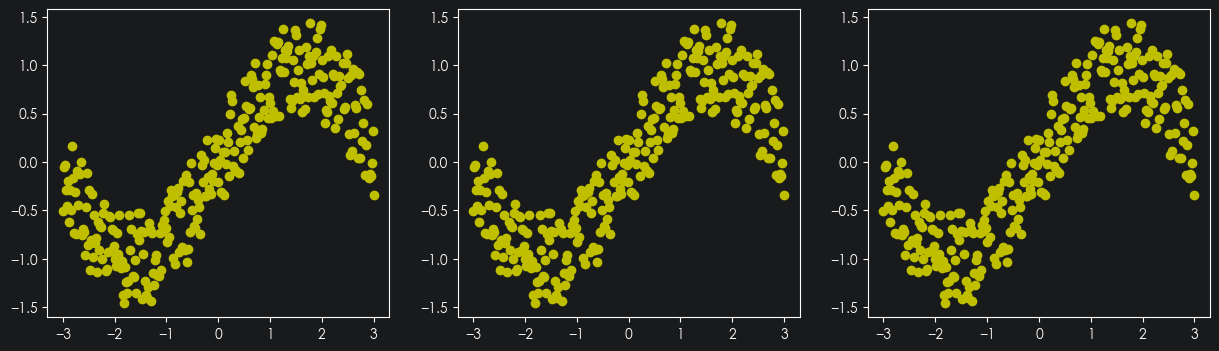

In [20]:

# 1. 生成数据
X = np.linspace(-3, 3, 300).reshape(-1, 1)      # (-1, 1),表示变为1列，行数自动计算【-1】
y = np.sin(X) + np.random.uniform(-0.5, 0.5, 300).reshape(-1, 1)
print(X.shape, y.shape)
# 画出散点图(3个子图)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(X, y, c='y')
ax[1].scatter(X, y, c='y')
ax[2].scatter(X, y, c='y')

# 2. 划分训练集和测试计集（验证集）
trainX, testX, trainY, testY = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. 定义模型（线性回归模型）
model = LinearRegression()

# 开始训练
4. 训练模型
5. 预测结果，计算损失loss function


In [30]:
'''欠拟合'''
# 欠拟合(直线)
x_train1 = trainX
x_test1 = testX
y_train1 = trainY
y_test1 = testY

# 4. 训练模型
model.fit(x_train1, trainY)
# 打印查看模型参数
print(model.coef_)              # 斜率
print(model.intercept_)         # 截距

# 5. 预测结果，计算损失loss function
y_pred1 = model.predict(x_test1)        # 测试数据的预测值
test_loss1 = mean_squared_error(y_test1, y_pred1)       # 测试误差
train_loss1 = mean_squared_error(y_train1, model.predict(x_train1)) # 训练误差

# 画出拟合曲线，并写出训练误差和测试误差
ax[0].plot(X, model.predict(X), 'r' )
ax[0].text(-3, 1 ,f'test loss is :{test_loss1:.4f}')
ax[0].text(-3, 1.3, f'train loss is :{train_loss1:.4f}')
print(f'test loss is :{test_loss1:.4f}')
print(f'train loss is :{train_loss1:.4f}')

[[0.34060052]]
[-0.01982074]
test loss is :0.2888
train loss is :0.2143


In [29]:
'''恰好拟合'''
poly5 = PolynomialFeatures(degree=5)    # 五次项，单会加一个0次项
x_train2 = poly5.fit_transform(trainX)
x_test2 = poly5.fit_transform(testX)
print(x_train2.shape, x_test2.shape)    # (240, 6) (60, 6)

# 4. 训练模型
model.fit(x_train2, trainY)

# 5. 预测结果，计算损失loss function
y_pred2 = model.predict(x_test2)        # 测试数据的预测值
test_loss2 = mean_squared_error(testY, y_pred2)       # 测试误差
train_loss2 = mean_squared_error(trainY, model.predict(x_train2)) # 训练误差

# 画出拟合曲线，并写出训练误差和测试误差
ax[1].plot(X, model.predict(poly5.fit_transform(X)), 'r' )
ax[1].text(-3, 1 ,f'test loss is :{test_loss2:.4f}')
ax[1].text(-3, 1.3, f"train loss is :{train_loss2:.4f}")
print(f'test loss is :{test_loss2:.4f}')
print(f'train loss is :{train_loss2:.4f}')

(240, 6) (60, 6)
test loss is :0.0739
train loss is :0.0806


In [28]:
'''过拟合（20次多项式）'''
poly20 = PolynomialFeatures(degree=20)    # 五次项，单会加一个0次项
x_train3 = poly20.fit_transform(trainX)
x_test3 = poly20.fit_transform(testX)
print(x_train3.shape, x_test3.shape)    # (240, 6) (60, 6)

# 4. 训练模型
model.fit(x_train3, trainY)

# 5. 预测结果，计算损失loss function
y_pred3 = model.predict(x_test3)        # 测试数据的预测值
test_loss3 = mean_squared_error(testY, y_pred3)       # 测试误差
train_loss3 = mean_squared_error(trainY, model.predict(x_train3)) # 训练误差

# 画出拟合曲线，并写出训练误差和测试误差
ax[2].plot(X, model.predict(poly20.fit_transform(X)), 'r' )
ax[2].text(-3, 1 ,f'test loss is :{test_loss3:.4f}')
ax[2].text(-3, 1.3, f"train loss is :{train_loss3:.4f}")
print(f'test loss is :{test_loss3:.4f}')
print(f'train loss is :{train_loss3:.4f}')

(240, 21) (60, 21)
test loss is :0.0800
train loss is :0.0772


# 绘图

ValueError: X has 6 features, but LinearRegression is expecting 1 features as input.

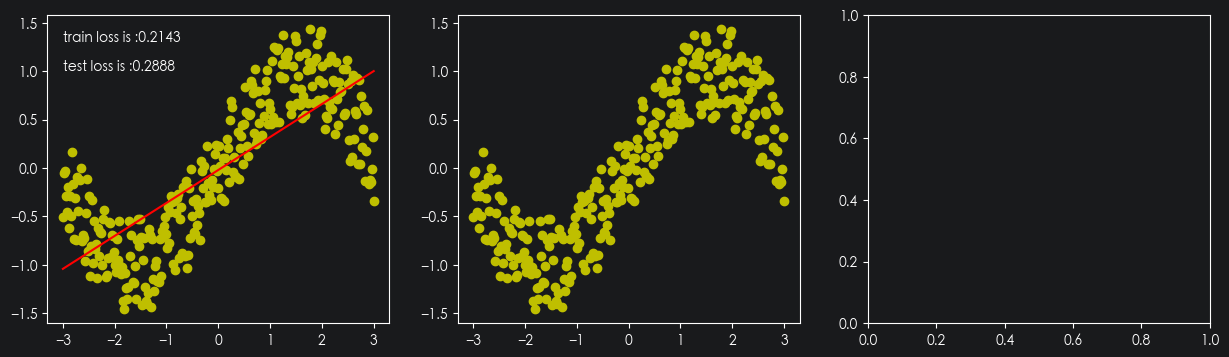

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(X, y, c='y')
ax[1].scatter(X, y, c='y')
ax[2].scatter(X, y, c='y')
# 欠拟合
ax[0].plot(X, model.predict(X), 'r' )
ax[0].text(-3, 1 ,f'test loss is :{test_loss1:.4f}')
ax[0].text(-3, 1.3, f'train loss is :{train_loss1:.4f}')
# 拟合
ax[1].plot(X, model.predict(poly5.fit_transform(X)), 'r' )
ax[1].text(-3, 1 ,f'test loss is :{test_loss2:.4f}')
ax[1].text(-3, 1.3, f"train loss is :{train_loss2:.4f}")
# 过拟合
ax[2].plot(X, model.predict(poly20.fit_transform(X)), 'r' )
ax[2].text(-3, 1 ,f'test loss is :{test_loss3:.4f}')
ax[2].text(-3, 1.3, f"train loss is :{train_loss3:.4f}")

plt.tight_layout()
plt.show()